In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## Description des variables

Le jeu de données contient **1 000 trajets de taxi** décrits par **11 variables** : 10 variables explicatives et 1 variable cible (`Trip_Price`).

| Variable | Type | Description | Valeurs / plage observée |
|---|---|---|---|
| `Trip_Distance_km` | Numérique (continue) | Distance parcourue pendant le trajet, en kilomètres | 1,23 – 146,07 km (médiane ≈ 25,8) |
| `Time_of_Day` | Catégorielle | Moment de la journée où le trajet a lieu | `Morning`, `Afternoon`, `Evening`, `Night` |
| `Day_of_Week` | Catégorielle | Type de jour du trajet | `Weekday` (semaine), `Weekend` (week-end) |
| `Passenger_Count` | Numérique (discrète) | Nombre de passagers à bord | 1 – 4 |
| `Traffic_Conditions` | Catégorielle (ordinale) | Niveau de congestion du trafic | `Low`, `Medium`, `High` |
| `Weather` | Catégorielle | Conditions météorologiques pendant le trajet | `Clear` (dégagé), `Rain` (pluie), `Snow` (neige) |
| `Base_Fare` | Numérique (continue) | Tarif de prise en charge, fixe au démarrage de la course | 2,01 – 5,00 |
| `Per_Km_Rate` | Numérique (continue) | Tarif appliqué par kilomètre parcouru | 0,50 – 2,00 |
| `Per_Minute_Rate` | Numérique (continue) | Tarif appliqué par minute de trajet | 0,10 – 0,50 |
| `Trip_Duration_Minutes` | Numérique (continue) | Durée totale du trajet, en minutes | 5,01 – 119,84 min (médiane ≈ 61,9) |
| **`Trip_Price`** | Numérique (continue) | **Variable cible** : prix total payé pour la course | 6,13 – 332,04 (médiane ≈ 50,1) |


In [2]:
# Import les données
df = pd.read_csv("taxi_trip_pricing.csv")
df.head()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,Morning,Weekday,3.0,Low,Clear,3.56,0.80,0.32,53.82,36.2624
1,47.59,Afternoon,Weekday,1.0,High,Clear,NaN,0.62,0.43,40.57,NaN
2,36.87,Evening,Weekend,1.0,High,Clear,2.70,1.21,0.15,37.27,52.9032
3,30.33,Evening,Weekday,4.0,Low,NaN,3.48,0.51,0.15,116.81,36.4698
4,NaN,Evening,Weekday,3.0,High,Clear,2.93,0.63,0.32,22.64,15.6180


In [3]:
# Dimension des données
df.shape

(1000, 11)

In [4]:
# Afficher les infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Trip_Distance_km       950 non-null    float64
 1   Time_of_Day            950 non-null    str    
 2   Day_of_Week            950 non-null    str    
 3   Passenger_Count        950 non-null    float64
 4   Traffic_Conditions     950 non-null    str    
 5   Weather                950 non-null    str    
 6   Base_Fare              950 non-null    float64
 7   Per_Km_Rate            950 non-null    float64
 8   Per_Minute_Rate        950 non-null    float64
 9   Trip_Duration_Minutes  950 non-null    float64
 10  Trip_Price             951 non-null    float64
dtypes: float64(7), str(4)
memory usage: 86.1 KB


### <font color = 'bisque'>Exploration et préparation des données

In [5]:
# sélection les variables quantitatives
quant_data = df.select_dtypes(include = "number")
quant_data.head()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
0,19.35,3.0,3.56,0.80,0.32,53.82,36.2624
1,47.59,1.0,NaN,0.62,0.43,40.57,NaN
2,36.87,1.0,2.70,1.21,0.15,37.27,52.9032
3,30.33,4.0,3.48,0.51,0.15,116.81,36.4698
4,NaN,3.0,2.93,0.63,0.32,22.64,15.6180


In [6]:
# décrire les variables quantitatives
quant_data.describe()

,Trip_Distance_km,Passenger_Count,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,951.000000
mean,27.070547,2.476842,3.502989,1.233316,0.292916,62.118116,56.874773
std,19.905300,1.102249,0.870162,0.429816,0.115592,32.154406,40.469791
min,1.230000,1.000000,2.010000,0.500000,0.100000,5.010000,6.126900
25%,12.632500,1.250000,2.730000,0.860000,0.190000,35.882500,33.742650
50%,25.830000,2.000000,3.520000,1.220000,0.290000,61.860000,50.074500
75%,38.405000,3.000000,4.260000,1.610000,0.390000,89.055000,69.099350
max,146.067047,4.000000,5.000000,2.000000,0.500000,119.840000,332.043689


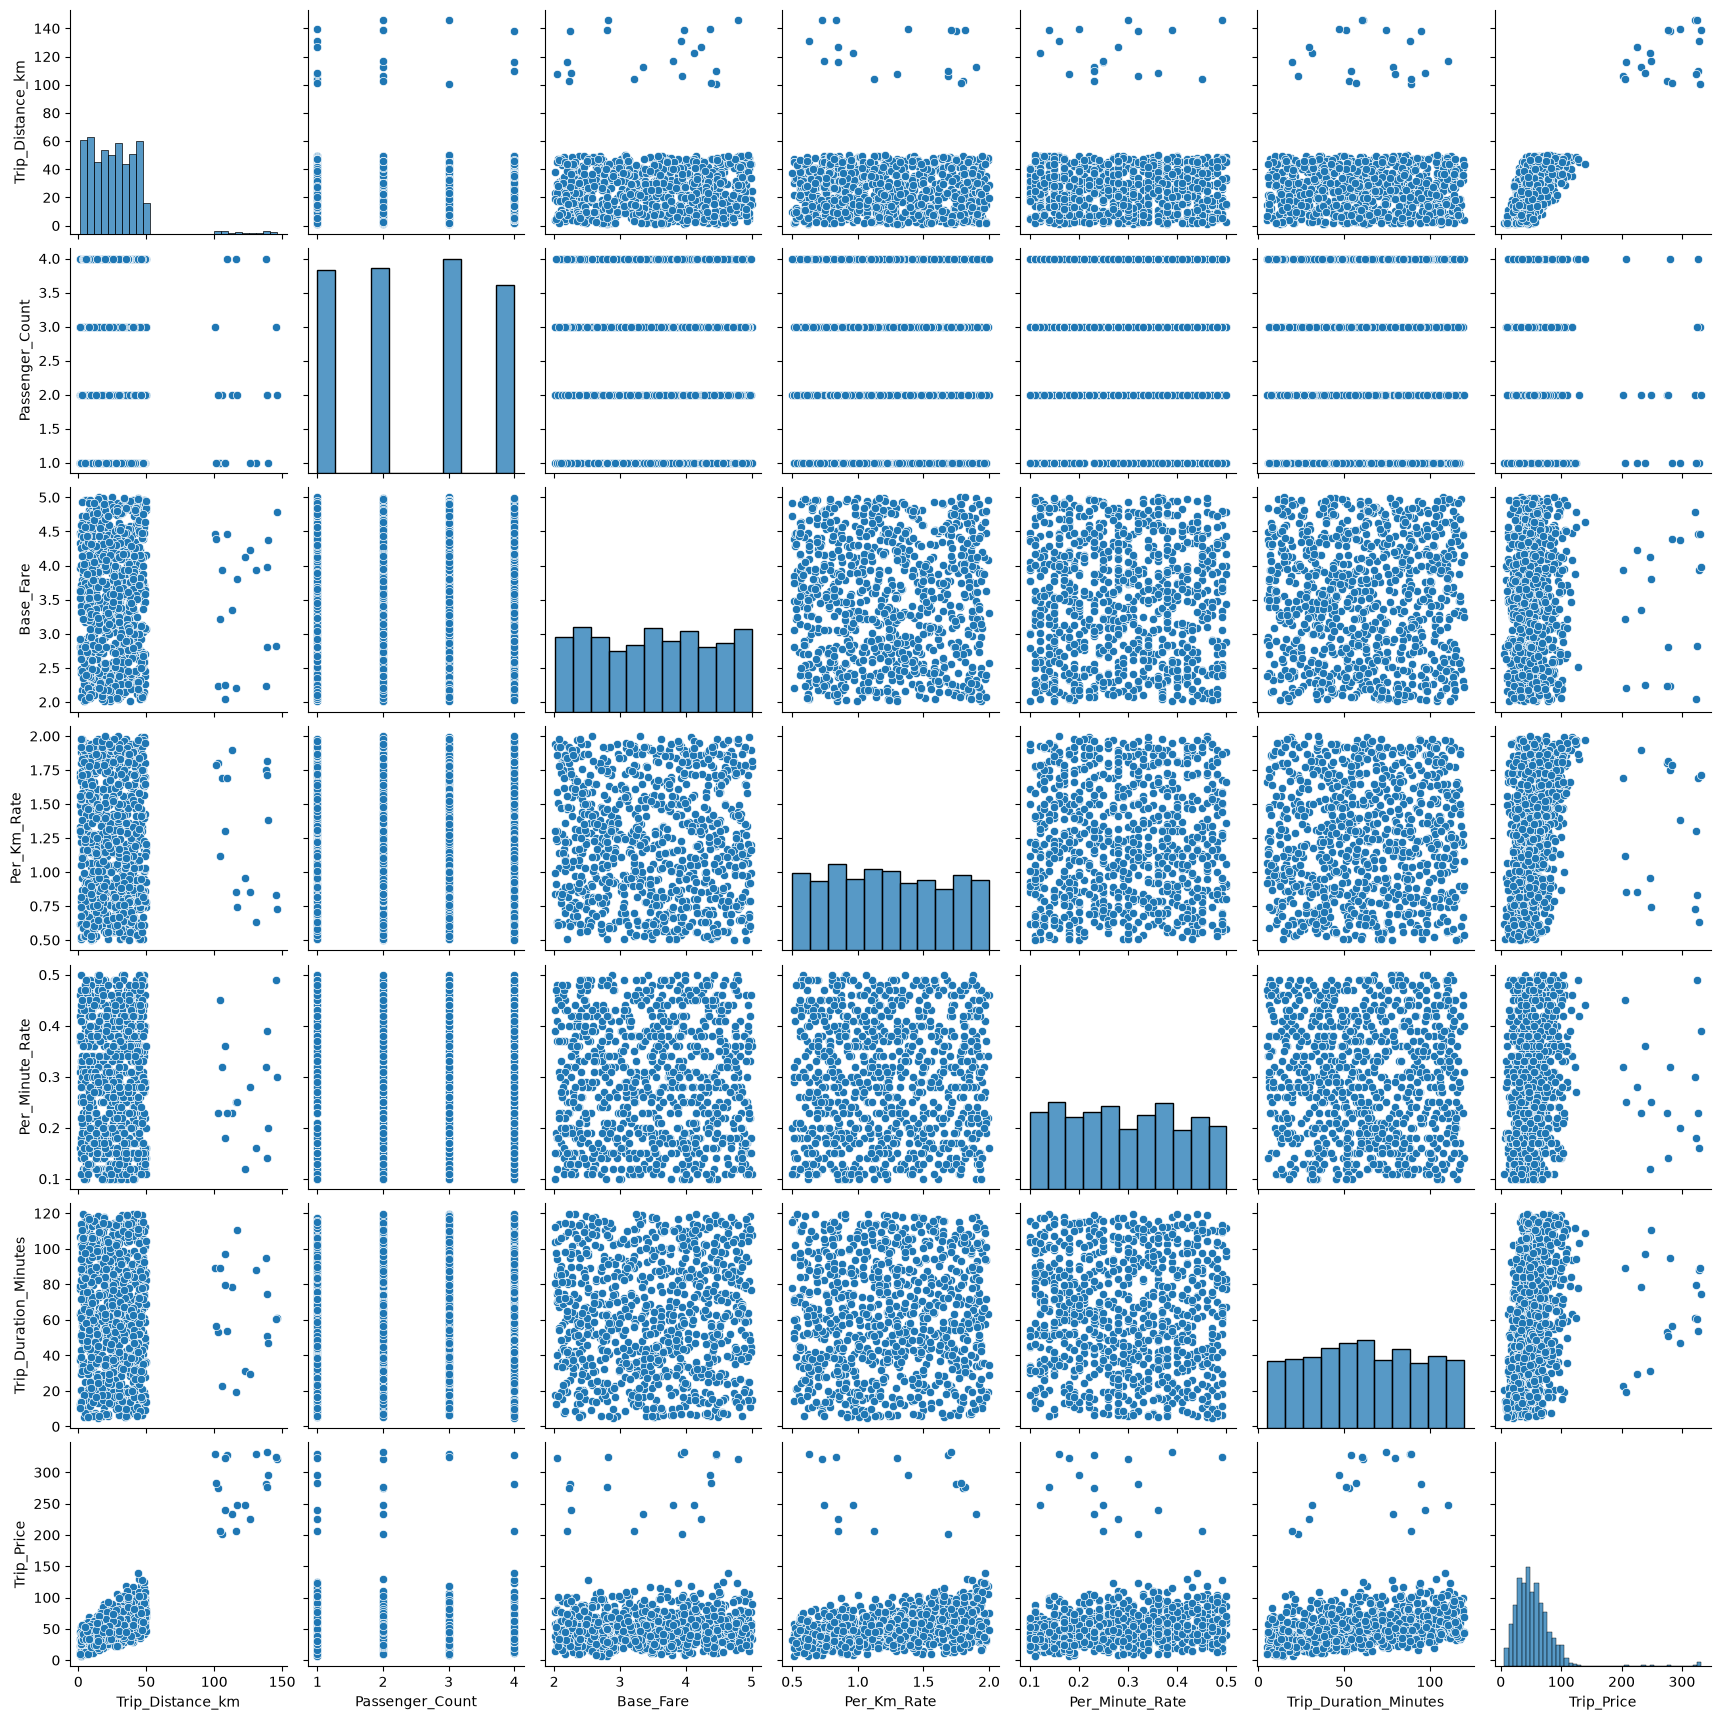

In [7]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

In [8]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df,x = col)
    fig.show()

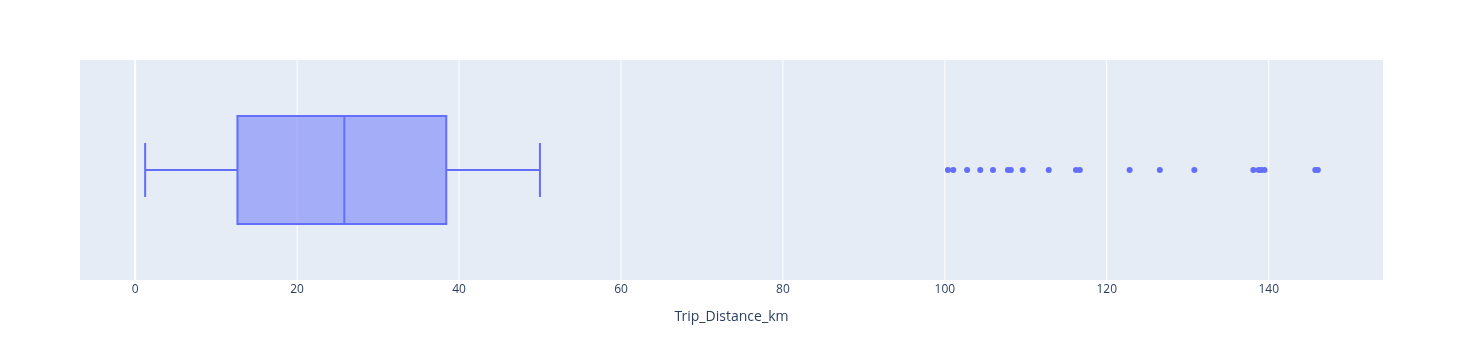

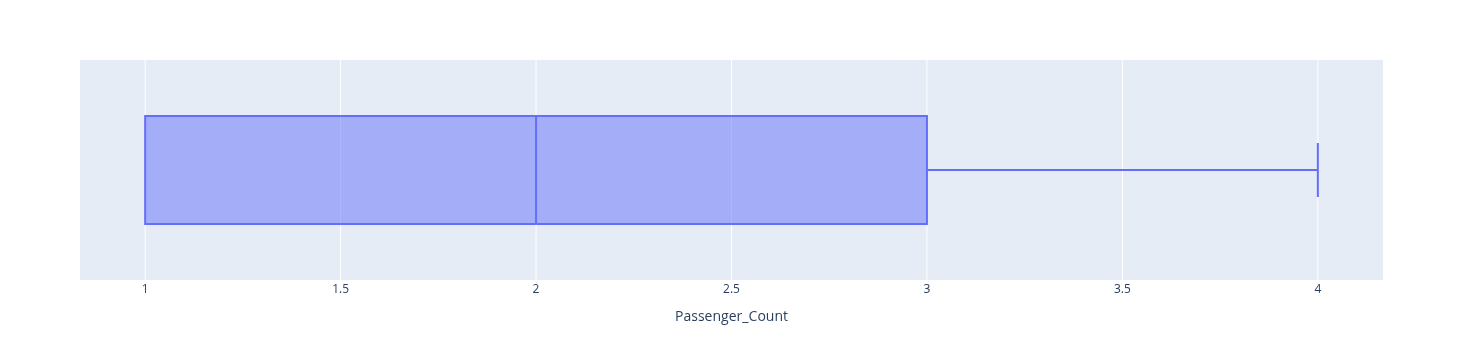

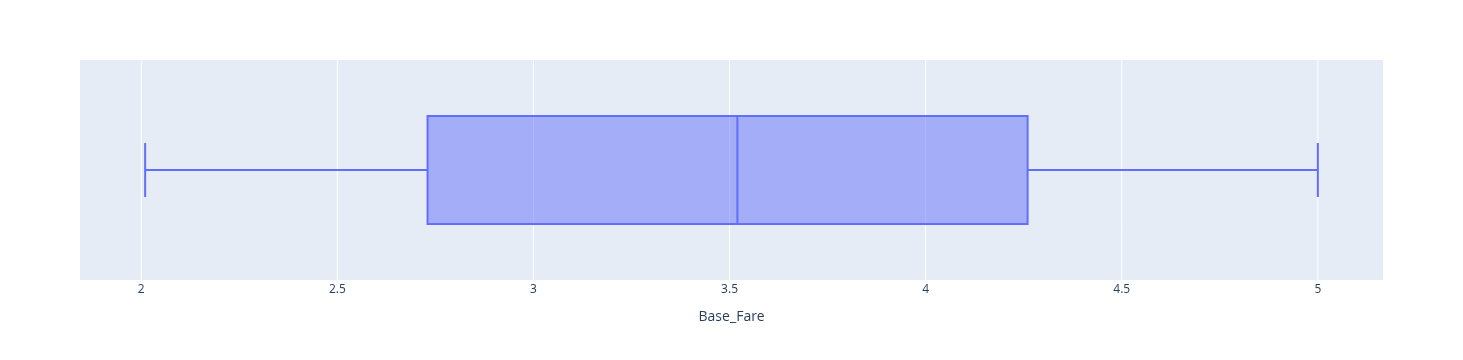

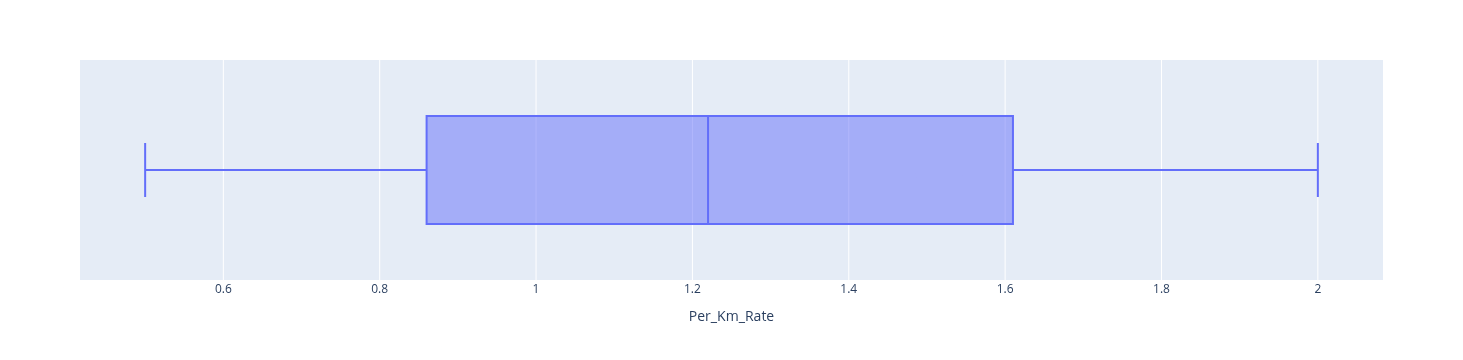

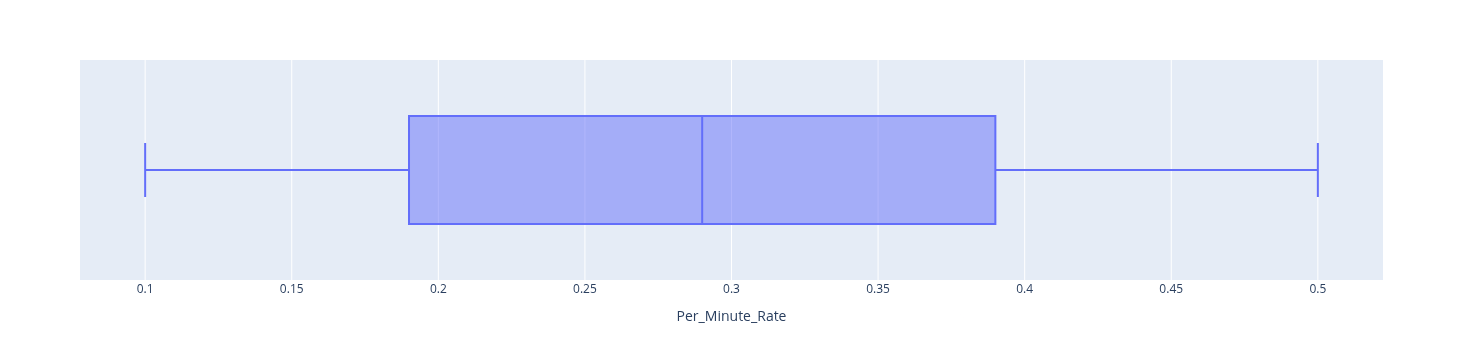

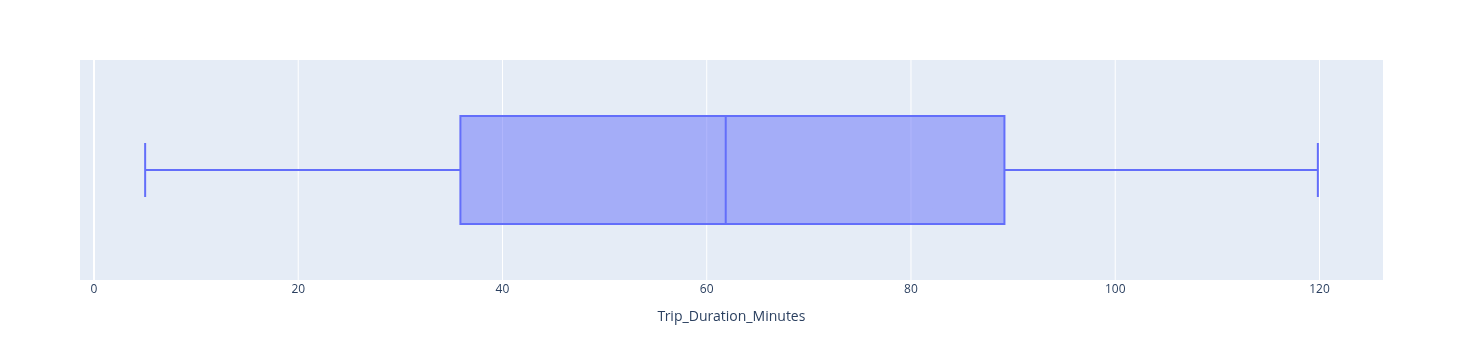

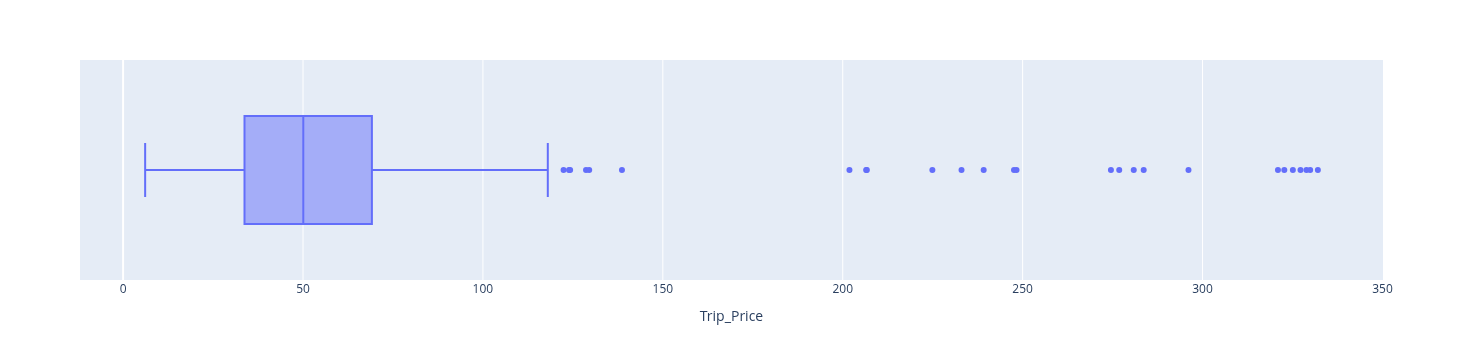

In [9]:
# Appliquer la fonctions boxplot_func
for col in quant_data.columns:
  boxplot_func(col)

<Axes: >

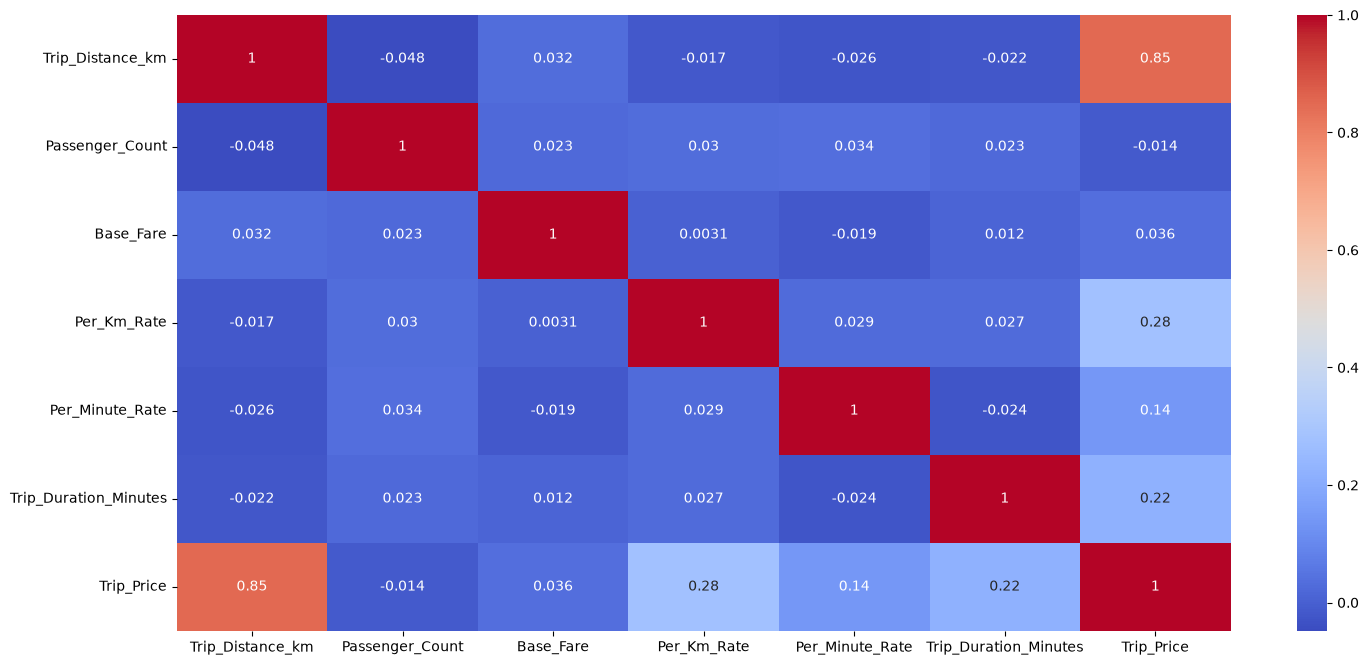

In [10]:
# Afficher la matrice de corrélation
plt.figure(figsize=(17,8))
sns.heatmap(quant_data.corr(), annot=True, cmap= "coolwarm")

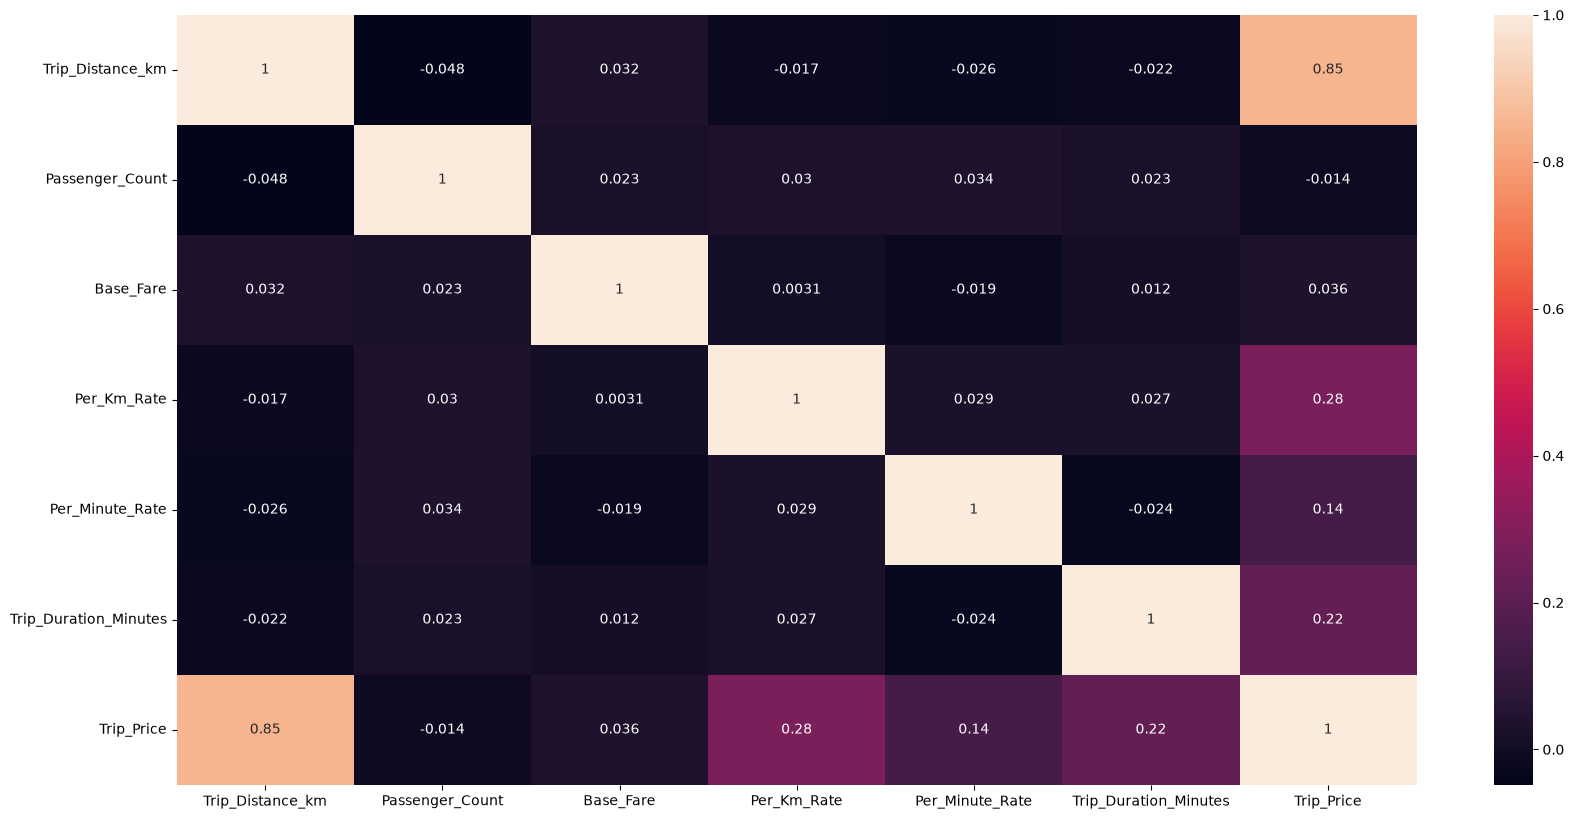

In [11]:
# Visualisaton le matrice de corrélation
plt.figure(figsize = (20, 10))
sns.heatmap(quant_data.corr(), annot = True)
plt.show()

In [12]:
# sélection les variables catégorielles
cat_data = df.select_dtypes(exclude = "number")

In [13]:
# Faire un describre
cat_data.describe()

,Time_of_Day,Day_of_Week,Traffic_Conditions,Weather
count,950,950,950,950
unique,4,2,3,3
top,Afternoon,Weekday,Low,Clear
freq,371,655,397,667


In [14]:
# Fonction de visualisaion du counplot
def countplot_func(col):
    val = cat_data[col].value_counts()
    fig = px.bar(x = val.index, y = val.values,color = val.index.astype(str), text_auto = True)
    fig.show()

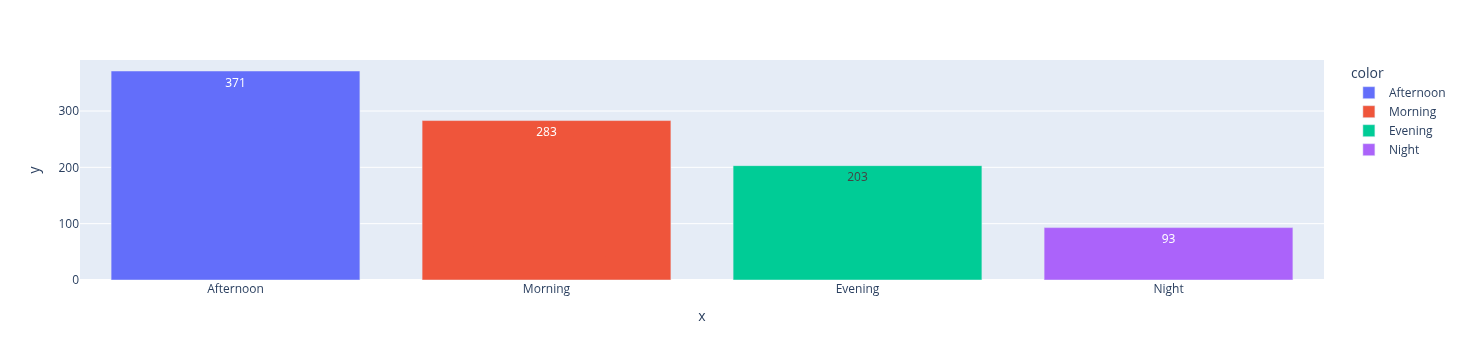

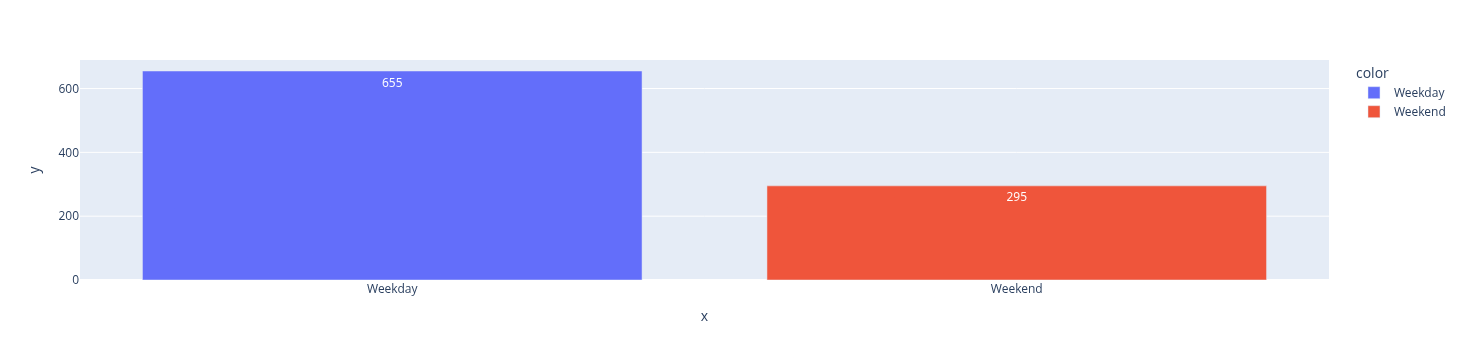

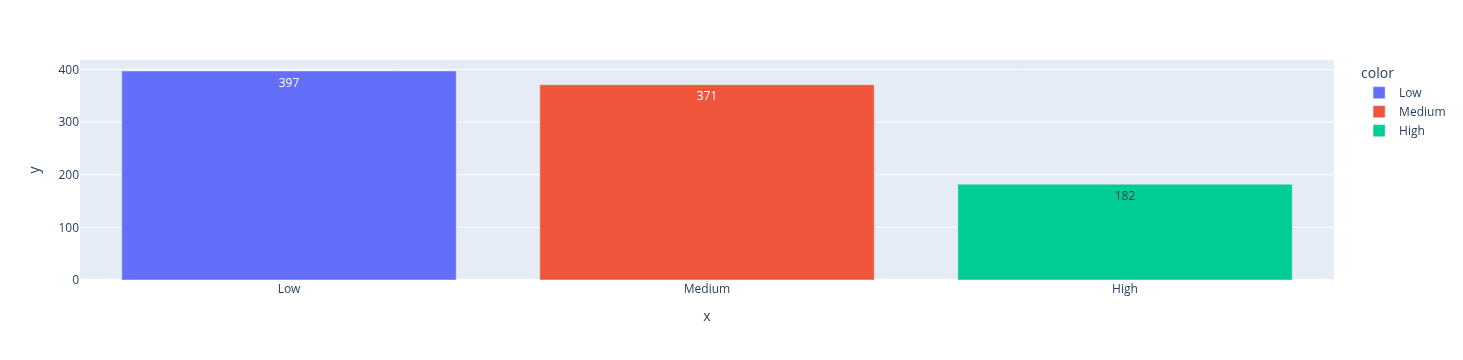

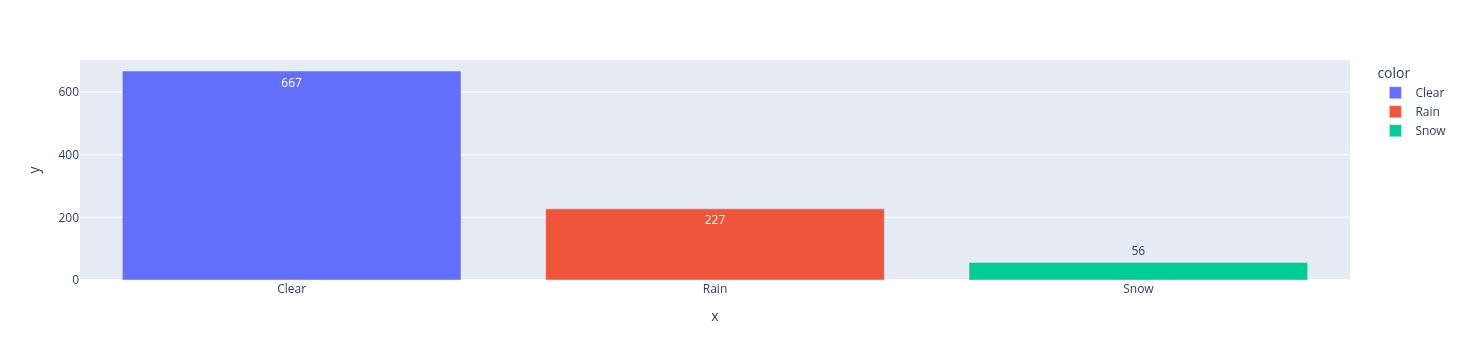

In [15]:
# Appliquer la fonction countplot_func
for col in cat_data:
    countplot_func(col)

In [16]:
# Imputer les valeurs manquantes des variables catégorielle en utilisant le mode
for col in cat_data.columns:
  df.fillna({col: df[col].mode()[0]}, inplace = True)

In [17]:
import joblib as jb
# Enregistrer les valeurs uniques des variables catégorielles (dict {colonne: valeurs})
# -> format attendu par l'application Streamlit (app.py)
uniques = {col: np.unique(df[col]).tolist() for col in cat_data.columns}
# sauvegarde dans le dossier models/ du déploiement
jb.dump(uniques, "./models/taxi_uniques.joblib")
uniques['Time_of_Day']

['Afternoon', 'Evening', 'Morning', 'Night']

In [18]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# un encodeur par variable catégorielle, rangé dans un dictionnaire {colonne: encoder}
# -> format attendu par l'application Streamlit (app.py)
encoders = {}
for col in cat_data.columns:
  encoder = LabelEncoder()
  encoder.fit(df[col]) # le modèle prend le temps de reconnaitre les classes
  df[col] = encoder.transform(df[col]) # encoder les valeurs
  encoders[col] = encoder

# classes de chaque variable, dans l'ordre de leurs codes
{col: encoders[col].classes_.tolist() for col in cat_data.columns}

{'Time_of_Day': ['Afternoon', 'Evening', 'Morning', 'Night'],
 'Day_of_Week': ['Weekday', 'Weekend'],
 'Traffic_Conditions': ['High', 'Low', 'Medium'],
 'Weather': ['Clear', 'Rain', 'Snow']}

In [19]:
# sauvegarde des encodeurs dans le dossier models/
jb.dump(encoders, "./models/taxi_encoders.joblib")

['./models/taxi_encoders.joblib']

In [20]:
from sklearn.impute import KNNImputer
# Imputer les valeurs manquantes des variables quantitatives
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

In [21]:
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan # NaN
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [22]:
# Application du traitement
for col in quant_data :
    impute_func(df,col)

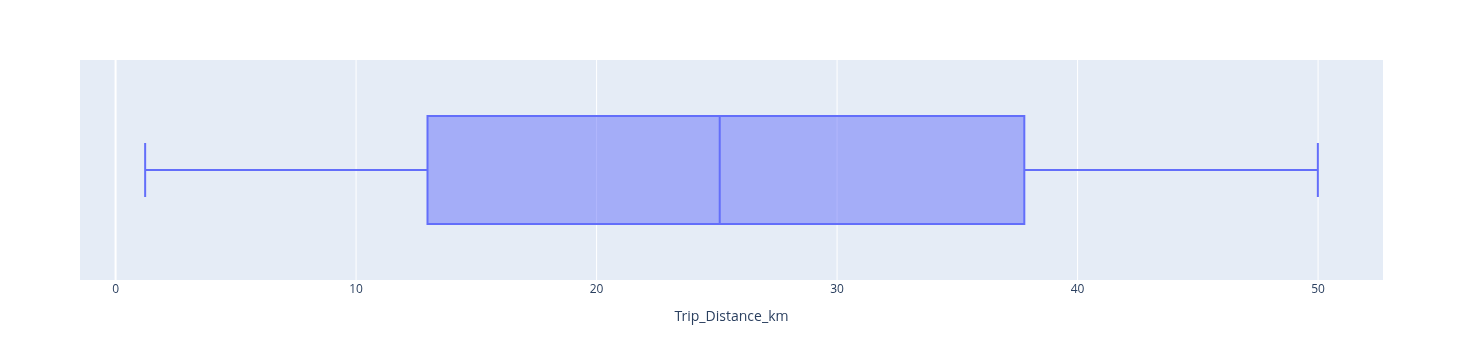

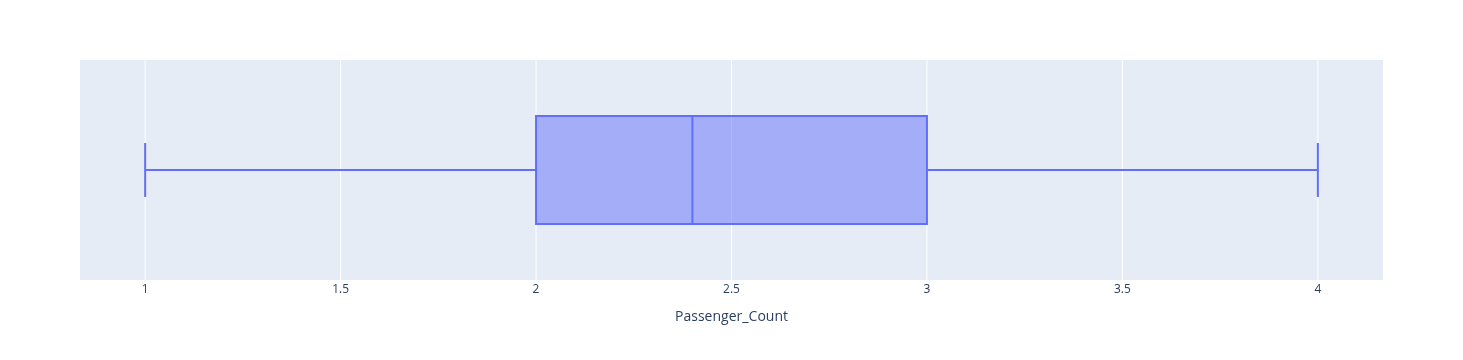

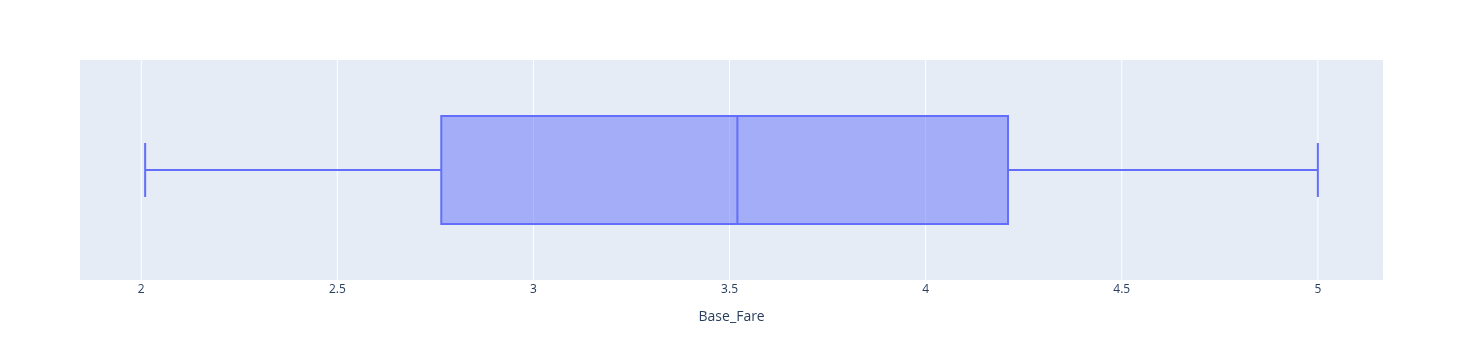

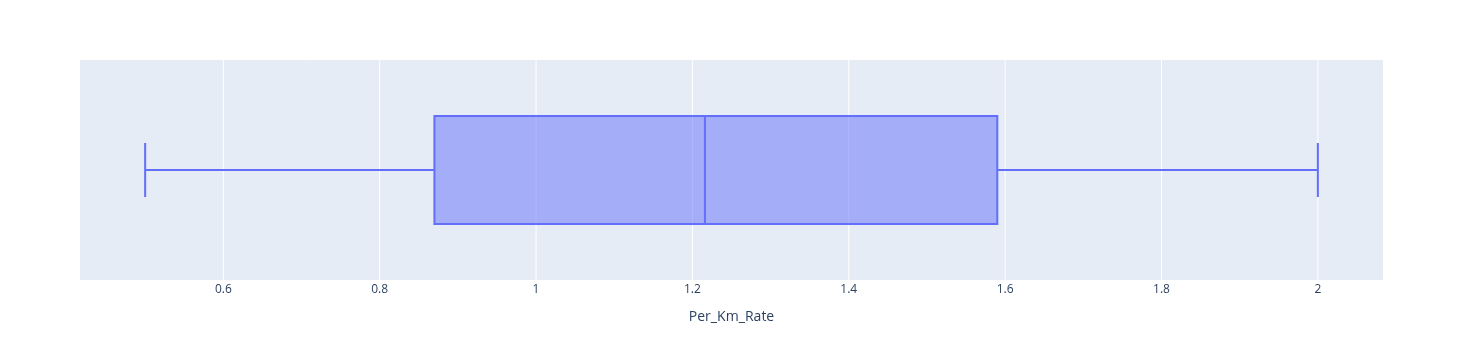

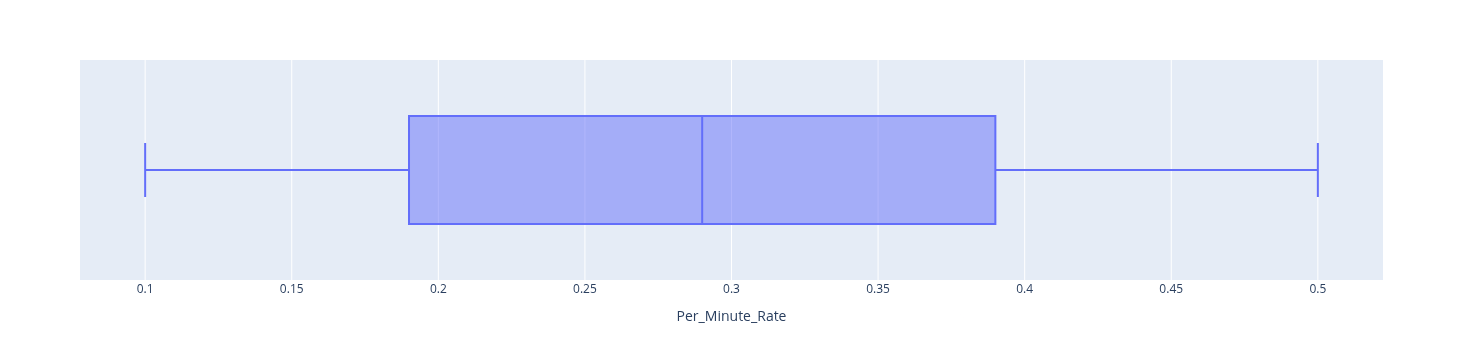

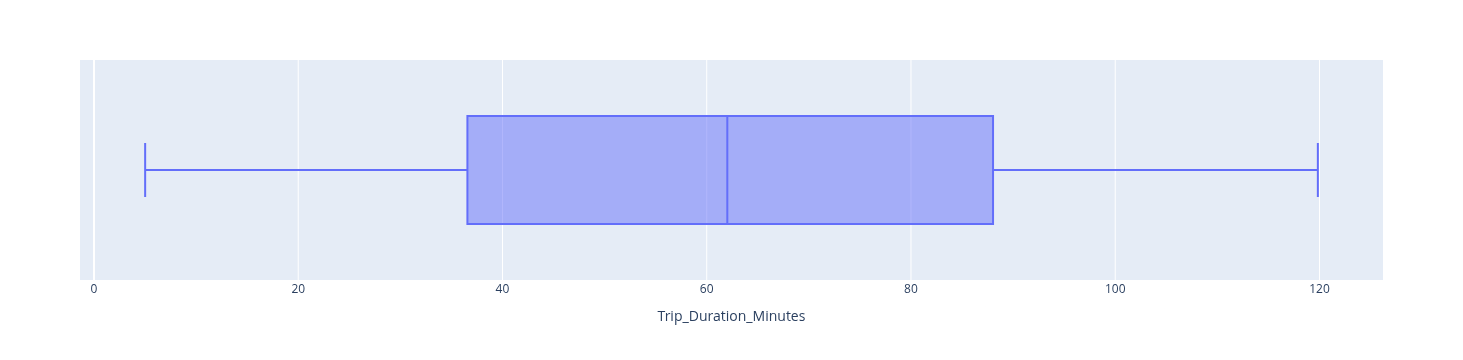

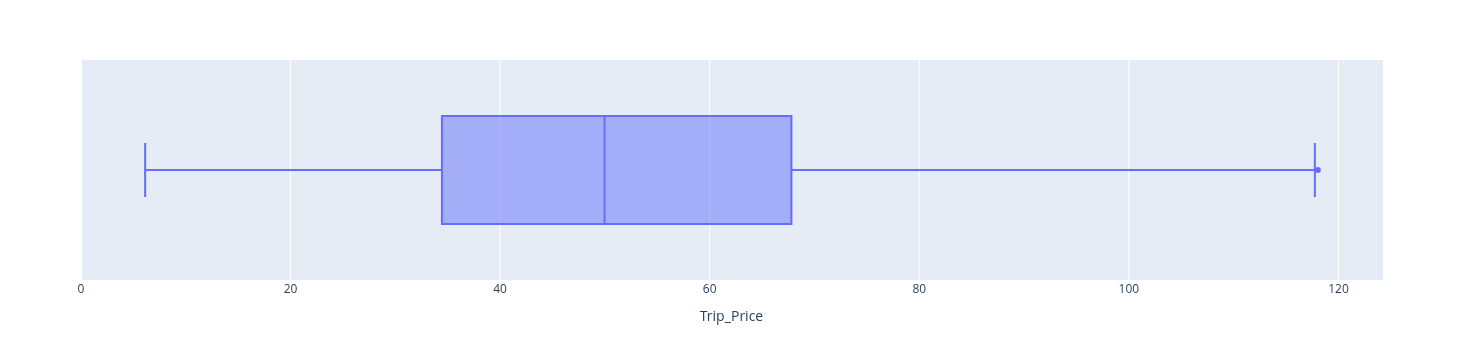

In [23]:
# réafficher les boxplots
for col in quant_data:
    boxplot_func(col)

In [24]:
# Fractionner les données
# ordre des variables explicatives (à respecter lors des prédictions)
features = df.columns[:-1].tolist()
jb.dump(features, "./models/taxi_features.joblib")
x = df.iloc[:,:-1].values
y = df.iloc[:, -1].values
features

['Trip_Distance_km',
 'Time_of_Day',
 'Day_of_Week',
 'Passenger_Count',
 'Traffic_Conditions',
 'Weather',
 'Base_Fare',
 'Per_Km_Rate',
 'Per_Minute_Rate',
 'Trip_Duration_Minutes']

In [25]:
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)

In [26]:
# sauvegarde du scaler dans le dossier models/
jb.dump(scaler, "./models/taxi_scaler.joblib")

['./models/taxi_scaler.joblib']

In [27]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

In [28]:
# verfication par affichage
x_train[:5]

array([[-0.88108926,  0.        ,  0.        , -0.4       ,  1.        ,
         0.        , -0.44367418,  0.75555556, -0.45      ,  0.31155828],
       [ 0.89440242,  0.5       ,  1.        , -1.4       , -1.        ,
         0.        , -0.56152513,  0.74166667, -0.75      ,  0.50034024],
       [ 0.23398891,  0.5       ,  0.        ,  1.6       ,  0.        ,
         1.        , -0.72790295,  0.13055556, -0.3       , -0.89987363],
       [-0.91618759, -0.5       ,  0.        , -0.4       ,  0.        ,
         0.        , -0.03466205, -0.48055556, -0.5       , -0.59793915],
       [ 0.83550177,  0.5       ,  1.        ,  0.6       ,  1.        ,
         0.        , -0.70710572, -0.89722222,  0.95      , -0.3755225 ]])

### <font color = 'bisque'>Multiple Linear Regression

In [29]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params_lr = {
    'fit_intercept': [True, False],
    'positive': [True, False]
 }
# Initialisation du modèle
lr = LinearRegression()
# Initialisation du GridSearchCV
grid_lr = GridSearchCV(lr, params_lr, cv = cv)
# Lancer la recherche
grid_lr.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosi

In [30]:
# Récupérer le modèle optimal en partant de gridsearch
lr_model = grid_lr.best_estimator_

#### <font color = 'teal'> Evaluation du Linear Regression<font>

In [31]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calculer le R2 score et Mean Squarred Error
# from math import *
def evaluation(model):
  y_pred = model.predict(x_val)
  r2 = r2_score(y_val, y_pred)
  mse = mean_squared_error(y_val, y_pred)
  mae = mean_absolute_error(y_val, y_pred)
  rmse = root_mean_squared_error(y_val, y_pred)
  return r2, mse, mae, rmse

In [32]:
# evaluation
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f"R2: {r2_lr}, mse: {mse_lr}, mae: {mae_lr}, rmse: {rmse_lr}")

R2: 0.864514089167485, mse: 71.61888514466979, mae: 6.7257093895859565, rmse: 8.462794168870573


### <font color = 'bisque'>Ridge Regression

In [33]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.linear_model import Ridge
# dictionnaire params
params_rr = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'alpha':np.logspace(-8,8, 100) #
 }
# Initialisation du modèle
rr = Ridge()
# Initialisation du GridSearchCV
grid_rr = GridSearchCV(rr, params_rr, cv = cv)
# Lancer la recherche
grid_rr.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([1.0000...00000000e+08]), 'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int,

In [34]:
# Récupérer le modèle optimal en partant de gridsearch
rr_model = grid_rr.best_estimator_

#### <font color = 'teal'> Evaluation du Ridge<font>

In [35]:
# Evaluation le modèle
r2_rr, mse_rr, mae_rr, rmse_rr = evaluation(lr_model)
print(f"R2: {r2_rr}, mse: {mse_rr}, mae: {mae_rr}, rmse: {rmse_rr}")

R2: 0.864514089167485, mse: 71.61888514466979, mae: 6.7257093895859565, rmse: 8.462794168870573


### <font color = 'bisque'>Decision Tree Regressor<font>

In [36]:
# Recherche des paramètres optimaux du decision tree
from sklearn.tree import DecisionTreeRegressor
# Dictionaire des params
params_dt = {
    'max_depth':np.arange(1,30),
    'criterion':['squared_error', 'absolute_error']
}
# Initialisation du modèle
dt = DecisionTreeRegressor(random_state = 42)
# Initialisation du GridSearchCV
grid_dt = GridSearchCV(dt, params_dt, cv = cv)
# Lancer la recherche
grid_dt.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'absolute_error'], 'max_depth': array([ 1, 2..., 27, 28, 29])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verb

In [37]:
# Récupérer le modèle optimal en partant de gridsearch
dr_model = grid_dt.best_estimator_

#### <font color = 'teal'> Evaluation du Decision Tree Regressor<font>

In [38]:
# Evaluation le modèle
r2_dr, mse_dr, mae_dr, rmse_dr = evaluation(dr_model)
print(f"R2: {r2_dr}, mse: {mse_dr}, mae: {mae_dr}, rmse: {rmse_dr}")

R2: 0.7921831661197742, mse: 109.85356237664904, mae: 8.01475512, rmse: 10.481105016965007


### <font color = 'bisque'>Random Forest Regressor<font>

In [39]:
from sklearn.ensemble import RandomForestRegressor

# Dictionnaires des paramètres
params_rf = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Initialisation du modèle
rf =  RandomForestRegressor()
# Objet grid
grid_rf = GridSearchCV(rf, params_rf, cv=cv)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 1, 2..., 12, 13, 14]), 'n_estimators': array([10, 20..., 70, 80, 90])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [40]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model = grid_rf.best_estimator_

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [41]:
# Evaluation le modèle
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model)
print(f"R2: {r2_rf}, mse: {mse_rf}, mae: {mae_rf}, rmse: {rmse_rf}")

R2: 0.9031878106038395, mse: 51.17566122088361, mae: 5.1280631099476315, rmse: 7.153716601940813


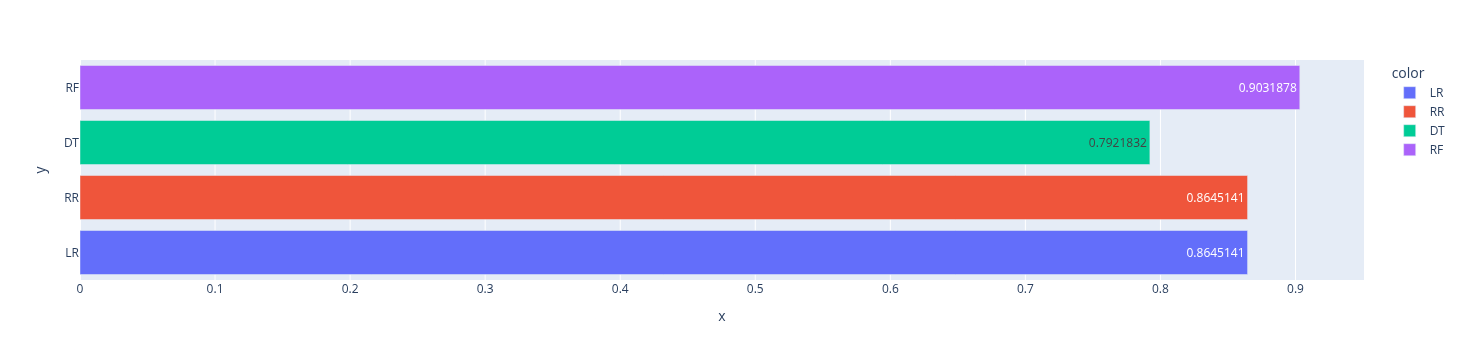

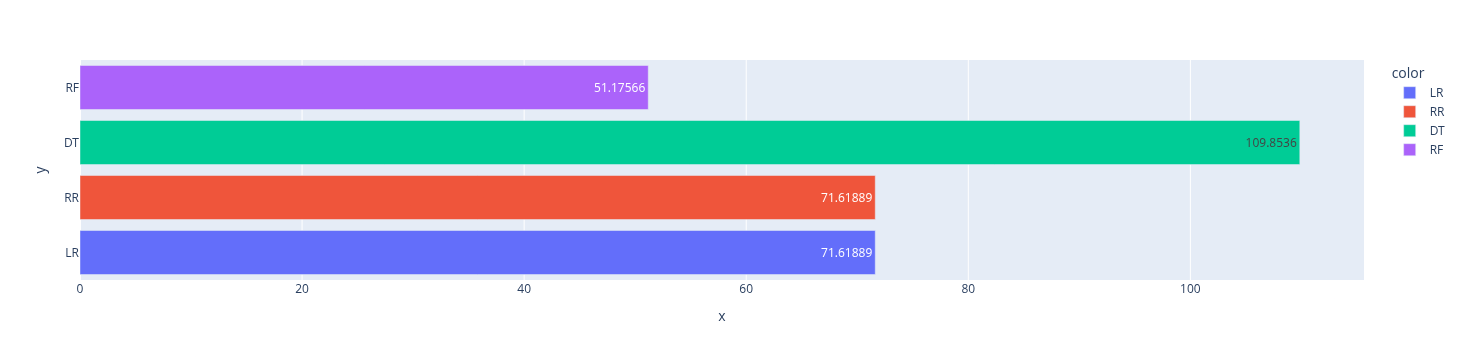

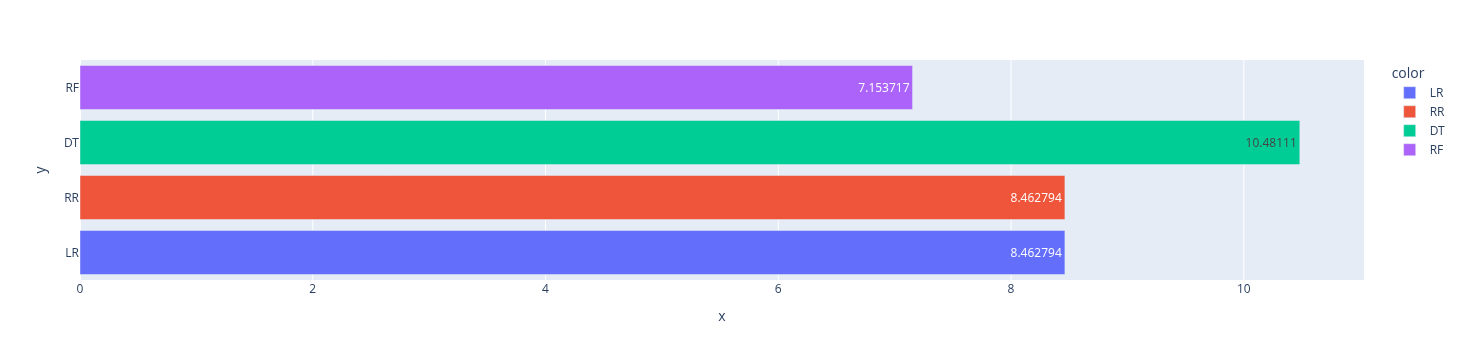

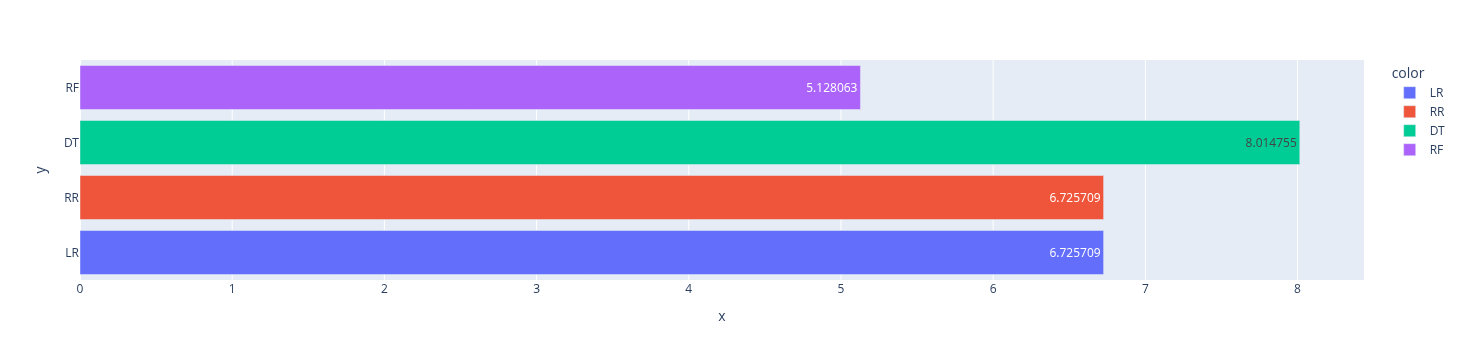

In [42]:
# comparaison des métriques
list_names = ["LR", "RR", "DT", "RF"]
list_r2 = [r2_lr, r2_rr, r2_dr, r2_rf]
list_mse = [mse_lr, mse_rr, mse_dr, mse_rf]
list_rmse= [rmse_lr, rmse_rr, rmse_dr, rmse_rf]
list_mae = [mae_lr, mae_rr, mae_dr, mae_rf]
list_final = [list_r2, list_mse, list_rmse, list_mae]

for i in range(4):
    fig = px.bar(y = list_names, x = list_final[i], color = list_names, text_auto = True)
    fig.show()

In [43]:
# télécharger le modèle le plus performant dans le dossier models/
jb.dump(rf_model, "./models/taxi_model.joblib")

['./models/taxi_model.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [44]:
#  echantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# Prédictions
y_pred_10 = rf_model.predict(x_test_10)
# Parcourir les prédictions
for i in range(10):
  print(f"Prédiction {i + 1} : {y_pred_10[i]:.2f}$ --Réel :{y_test_10[i]:.2f}$")

Prédiction 1 : 12.31$ --Réel :13.06$
Prédiction 2 : 16.05$ --Réel :12.73$
Prédiction 3 : 75.85$ --Réel :86.90$
Prédiction 4 : 26.09$ --Réel :29.86$
Prédiction 5 : 53.03$ --Réel :57.08$
Prédiction 6 : 46.86$ --Réel :46.81$
Prédiction 7 : 42.02$ --Réel :40.36$
Prédiction 8 : 73.43$ --Réel :81.85$
Prédiction 9 : 31.62$ --Réel :27.16$
Prédiction 10 : 52.29$ --Réel :54.44$


### <font color = 'teal'>Déploiement<font>

Le déploiement est réalisé avec **Streamlit** dans `app.py` (page 🚕 Taxi).
Fichiers produits dans `models/` :
`taxi_model.joblib`, `taxi_encoders.joblib`, `taxi_scaler.joblib`, `taxi_uniques.joblib`, `taxi_features.joblib`.

In [ ]:
# (ancien déploiement Gradio remplacé par Streamlit — voir app.py)